# RBC NOB ΔT = 40 K (cv12) — 최적화 전(원본 f330720) vs 후(현재) 통계 비교

`input_rbc_nob_cv12_dt40_val_{orig,new}.ini`: 128×128×256, Ra 1e6, Pr 2547, npz 4 (V100 ×4, gpu17 / gpu16), 같은 냉시작(결정론적 섭동)에서 t 25000 까지, 통계 창 **t 16900~25000** (누적 파일 1000 마다).
원본 = `build_gpu/bin/rbc_nob_validate_orig`(원본 코드 + 계측 main), 현재 = `rbc_nob_validate_new`. 참조 = 이전 클러스터 완주(잡 36135, npz 2): θ_c 0.13852 / Nu 9.597, Horn 2013 T_c +0.2 %.
그림은 `docs/Scalability/validation/rbc_dt40_*.png` 에 저장.

In [ ]:
import glob, re, os
import numpy as np
import matplotlib
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "legend.fontsize": 8, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})
SAVE_FIG = True
FIG_DIR = os.path.join(os.path.dirname(os.path.dirname(os.getcwd())), "docs", "Scalability", "validation"); os.makedirs(FIG_DIR, exist_ok=True)
def save(fig, name):
    if SAVE_FIG: fig.savefig(os.path.join(FIG_DIR, name), dpi=130, bbox_inches="tight"); print("saved", os.path.relpath(os.path.join(FIG_DIR, name), os.getcwd()))
STYLE = {"orig": dict(color="#9a9a96", ls="--", marker="o", mfc="white", ms=5, mew=1.2), "new": dict(color="#2a78d6", ls="-", marker="s", ms=3)}
REF = {"theta_c": 0.13852, "Nu": 9.597}
LOGS = {"orig": sorted(glob.glob("log/dt40_orig_*.log")), "new": sorted(glob.glob("log/dt40_new_*.log"))}
def load_stats(path):
    hdr, rows = {}, []
    for l in open(path):
        if l.startswith("#"):
            for k, v in re.findall(r"(\w+)=([-+0-9.eE]+)", l): hdr[k] = float(v)
        elif l.strip(): rows.append([float(x) for x in l.split()])
    return hdr, np.array(rows)
def monitor(log):
    t, th, nub, nut = [], [], [], []
    for l in open(log):
        if re.match(r"^\s*\d+\s", l):
            f = l.split(); t.append(float(f[1])); th.append(float(f[4])); nub.append(float(f[8])); nut.append(float(f[9]))
    return np.array(t), np.array(th), np.array(nub), np.array(nut)
RUNS = {v: sorted(glob.glob(f"stats_val_dt40_{v}/rbc_nob_stats_*.dat")) for v in ("orig", "new")}
HAVE = [v for v in ("orig", "new") if RUNS[v]]
FINAL = {v: load_stats(RUNS[v][-1]) for v in HAVE}
SERIES = {v: [load_stats(f)[0] for f in RUNS[v]] for v in HAVE}
MON = {v: monitor(LOGS[v][-1]) for v in ("orig", "new") if LOGS[v]}
TITLE = "RBC NOB ΔT 40, 128×128×256, V100 ×4"
keys = ["theta_c", "Nu_volume", "Nu_bottom", "Nu_top", "lambda_theta_b", "lambda_theta_t", "chi_lambda_theta", "Re_E_m", "Re_E_c", "Re_pl_m", "T_rms_center"]
print(f"{'quantity':18s}" + "".join(f"{v:>12s}" for v in HAVE) + ("   diff" if len(HAVE) == 2 else "") + "   (window t_start→t)")
for k in keys:
    row = f"{k:18s}" + "".join(f"{FINAL[v][0][k]:12.5g}" for v in HAVE)
    if len(HAVE) == 2: row += f"  {100*(FINAL['new'][0][k]-FINAL['orig'][0][k])/FINAL['orig'][0][k]:+6.2f}%"
    print(row)
for v in HAVE: print(f"   {v}: window {FINAL[v][0]['t_start']:.0f}→{FINAL[v][0]['t']:.0f} (sum_dt {FINAL[v][0]['sum_dt']:.0f})")
print(f"reference (old cluster, npz 2, window 16900→25000): theta_c {REF['theta_c']} / Nu {REF['Nu']}")

quantity                  orig         new   diff   (window t_start→t)
theta_c                0.13901     0.13841   -0.43%
Nu_volume                9.736      9.7189   -0.18%
Nu_bottom               9.7993      9.7753   -0.24%
Nu_top                  9.8048      9.7939   -0.11%
lambda_theta_b        0.037123    0.037276   +0.41%
lambda_theta_t         0.06467     0.06468   +0.02%
chi_lambda_theta         1.742      1.7352   -0.39%
Re_E_m                  0.0924      0.0929   +0.54%
Re_E_c                  0.1371      0.1375   +0.29%
Re_pl_m                 0.5666      0.5261   -7.15%
T_rms_center           0.03374     0.03365   -0.27%
   orig: window 16900→25000 (sum_dt 8100)
   new: window 16900→25000 (sum_dt 8100)
reference (old cluster, npz 2, window 16900→25000): theta_c 0.13852 / Nu 9.597


## 1. 시간 이력 — 모니터의 θ_c, Nu_b/Nu_t (전 구간; 음영 = 통계 창)

saved ../../docs/Scalability/validation/rbc_dt40_history.png
theta_c identical at print precision until t = 10695


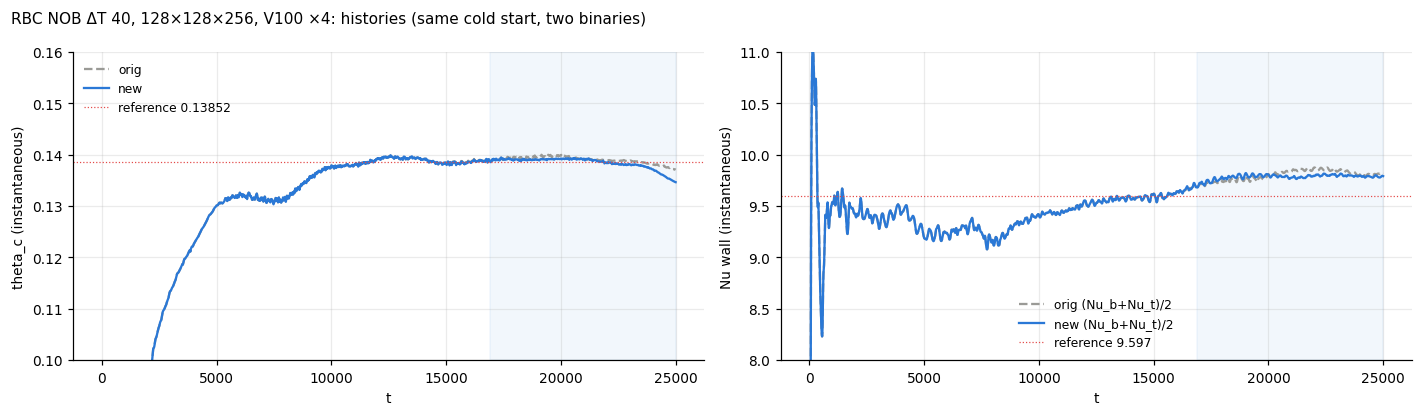

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for v, (t, th, nub, nut) in MON.items():
    axes[0].plot(t, th, label=v, **{**STYLE[v], "marker": None}); axes[1].plot(t, 0.5 * (nub + nut), label=f"{v} (Nu_b+Nu_t)/2", **{**STYLE[v], "marker": None})
axes[0].axhline(REF["theta_c"], color="#e34948", lw=0.8, ls=":", label="reference 0.13852"); axes[1].axhline(REF["Nu"], color="#e34948", lw=0.8, ls=":", label="reference 9.597")
for ax, yl in zip(axes, ("theta_c (instantaneous)", "Nu wall (instantaneous)")):
    ax.axvspan(16900, 25000, color="#2a78d6", alpha=0.06); ax.set_xlabel("t"); ax.set_ylabel(yl); ax.legend(frameon=False)
axes[0].set_ylim(0.10, 0.16); axes[1].set_ylim(8, 11)
fig.suptitle(f"{TITLE}: histories (same cold start, two binaries)", x=0.01, ha="left", fontsize=10); fig.tight_layout(); save(fig, "rbc_dt40_history.png"); plt.show()
# 결정론적 구간: 두 로그가 출력 정밀도에서 같은 마지막 t
if len(MON) == 2:
    m = min(len(MON["orig"][0]), len(MON["new"][0])); d = np.abs(MON["new"][1][:m] - MON["orig"][1][:m])
    k = np.argmax(d > 0) if (d > 0).any() else None
    print("theta_c identical at print precision until t =", f"{MON['orig'][0][k-1]:.0f}" if k else "end of shorter log")

## 2. 통계 창 프로파일 — ⟨T⟩(z), u/v/w/T rms, ⟨wT⟩, Nu_z: 원본(○ 파선) vs 현재(■ 실선)

saved ../../docs/Scalability/validation/rbc_dt40_profiles.png
profile max|diff|/max|orig|: T_mean 0.17%, u_rms 2.77%, w_rms 0.47%, T_rms 0.20%, wT_mean 0.47%, Nu_z 0.24%


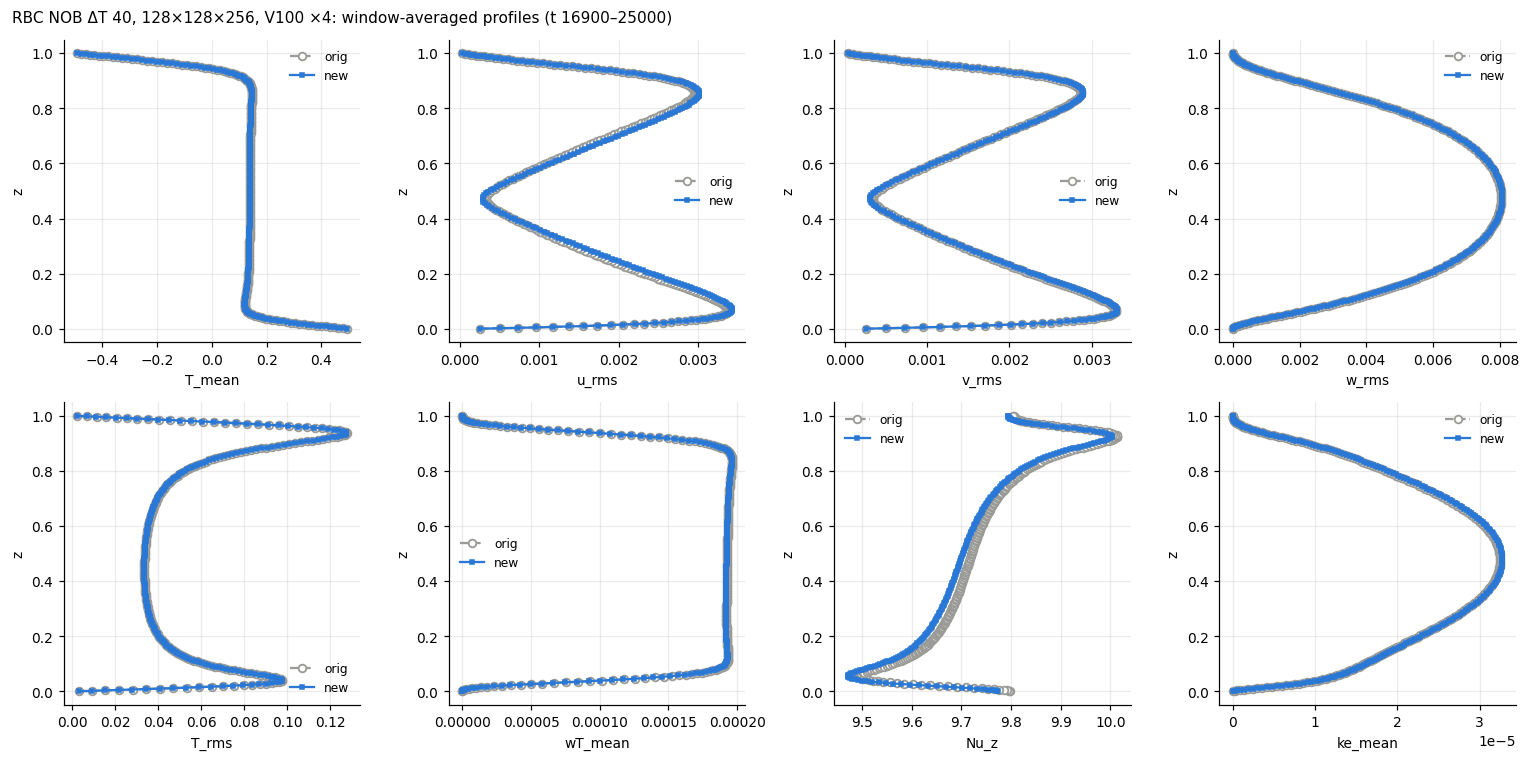

In [ ]:
cols = ["z", "T_mean", "u_rms", "v_rms", "w_rms", "T_rms", "wT_mean", "Nu_z", "kappa_mean", "mu_mean", "ke_mean"]
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, c in zip(axes.flat, ["T_mean", "u_rms", "v_rms", "w_rms", "T_rms", "wT_mean", "Nu_z", "ke_mean"]):
    i = cols.index(c)
    for v in HAVE:
        d = FINAL[v][1]; ax.plot(d[:, i], d[:, 0], label=v, **STYLE[v])
    ax.set_xlabel(c); ax.set_ylabel("z"); ax.legend(frameon=False)
fig.suptitle(f"{TITLE}: window-averaged profiles (t {FINAL[HAVE[0]][0]['t_start']:.0f}–{FINAL[HAVE[0]][0]['t']:.0f})", x=0.01, ha="left", fontsize=10); fig.tight_layout(); save(fig, "rbc_dt40_profiles.png"); plt.show()
if len(HAVE) == 2:
    print("profile max|diff|/max|orig|:", ", ".join(f"{c} {100*np.max(np.abs(FINAL['new'][1][:, cols.index(c)]-FINAL['orig'][1][:, cols.index(c)]))/max(np.max(np.abs(FINAL['orig'][1][:, cols.index(c)])), 1e-300):.2f}%" for c in ("T_mean", "u_rms", "w_rms", "T_rms", "wT_mean", "Nu_z")))

## 3. 누적 창(16900 → t)에 따른 θ_c·Nu·λ_θ·Re 수렴 — 창 변동 폭이 전/후 차이의 척도

saved ../../docs/Scalability/validation/rbc_dt40_convergence.png


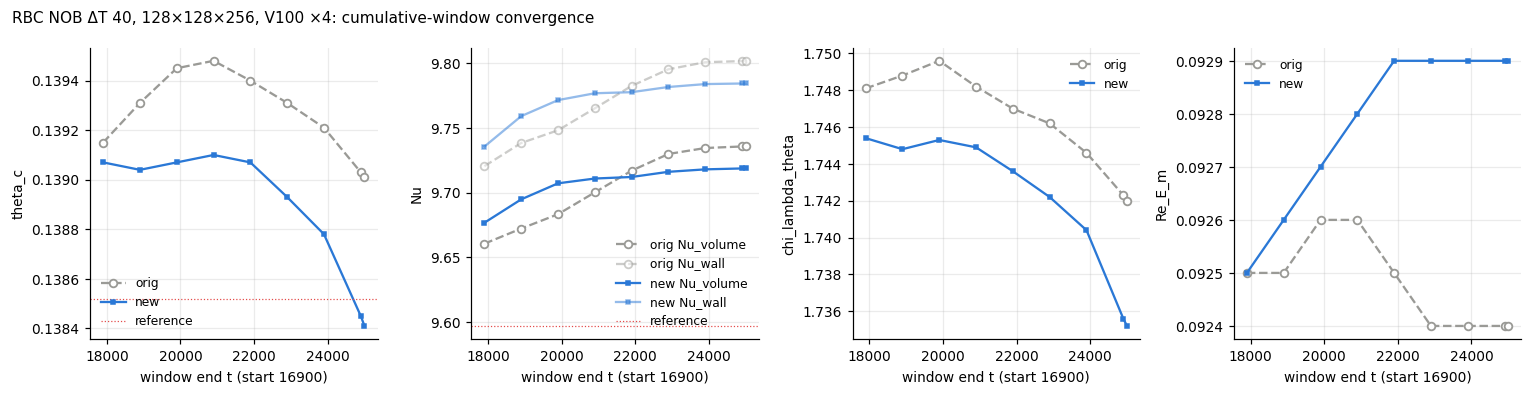

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for v in HAVE:
    t = [h["t"] for h in SERIES[v]]
    axes[0].plot(t, [h["theta_c"] for h in SERIES[v]], label=v, **STYLE[v])
    axes[1].plot(t, [h["Nu_volume"] for h in SERIES[v]], label=f"{v} Nu_volume", **STYLE[v]); axes[1].plot(t, [0.5*(h["Nu_bottom"]+h["Nu_top"]) for h in SERIES[v]], label=f"{v} Nu_wall", alpha=0.5, **STYLE[v])
    axes[2].plot(t, [h["chi_lambda_theta"] for h in SERIES[v]], label=v, **STYLE[v])
    axes[3].plot(t, [h["Re_E_m"] for h in SERIES[v]], label=v, **STYLE[v])
axes[0].axhline(REF["theta_c"], color="#e34948", lw=0.8, ls=":", label="reference"); axes[1].axhline(REF["Nu"], color="#e34948", lw=0.8, ls=":", label="reference")
for ax, yl in zip(axes, ("theta_c", "Nu", "chi_lambda_theta", "Re_E_m")): ax.set_xlabel("window end t (start 16900)"); ax.set_ylabel(yl); ax.legend(frameon=False)
fig.suptitle(f"{TITLE}: cumulative-window convergence", x=0.01, ha="left", fontsize=10); fig.tight_layout(); save(fig, "rbc_dt40_convergence.png"); plt.show()